# Распознавание рукописных символов с помощью CNN

## Цель проекта

Построить модель компьютерного зрения, которая классифицирует рукописные цифры и латинские буквы. В качестве данных используется EMNIST ByClass - расширение MNIST с 62 классами: 10 цифр, 26 заглавных и 26 строчных букв.

Проект включает:

- исследование изображений и распределения классов;
- подготовку данных и аугментации;
- обучение сверточной нейронной сети;
- оценку на отложенной тестовой выборке;
- анализ наиболее частых ошибок;
- демонстрацию предсказаний модели.

Классификация отдельных символов является базовым компонентом OCR-системы. Полноценное распознавание документов также требует надежной сегментации строк и символов.

## Режим запуска

В быстром режиме используется стратифицированная часть EMNIST и три эпохи. Этого достаточно, чтобы проверить весь pipeline в Google Colab. Для финального эксперимента перед публикацией нужно установить `FAST_RUN = False` и выполнить ноутбук целиком.

In [1]:
import random
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

In [2]:
SEED = 42
FAST_RUN = False
BATCH_SIZE = 256
EPOCHS = 3 if FAST_RUN else 8
MAX_TRAIN_SAMPLES = 150_000 if FAST_RUN else None
MAX_VAL_SAMPLES = 20_000 if FAST_RUN else None
MAX_TEST_SAMPLES = 30_000 if FAST_RUN else None

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")
print(f"Режим: {'быстрый' if FAST_RUN else 'финальный'}")

Устройство: cuda
Режим: финальный


## Загрузка и подготовка данных

Изображения EMNIST имеют размер 28 x 28 пикселей и хранятся в повернутом виде. Перед обучением ориентация исправляется. Для обучающей выборки добавляются небольшие случайные повороты и сдвиги. Они помогают модели устойчивее распознавать вариации почерка.

Разделение на обучение и валидацию выполняется со стратификацией, поэтому доли классов сохраняются.

In [3]:
def fix_orientation(image):
    return TF.hflip(TF.rotate(image, -90))


train_transform = transforms.Compose([
    transforms.Lambda(fix_orientation),
    transforms.RandomAffine(degrees=8, translate=(0.08, 0.08), scale=(0.92, 1.08)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

eval_transform = transforms.Compose([
    transforms.Lambda(fix_orientation),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [4]:
data_root = "data"

train_raw = datasets.EMNIST(
    root=data_root,
    split="byclass",
    train=True,
    download=True
)

train_augmented = datasets.EMNIST(
    root=data_root,
    split="byclass",
    train=True,
    download=False,
    transform=train_transform
)

train_evaluation = datasets.EMNIST(
    root=data_root,
    split="byclass",
    train=True,
    download=False,
    transform=eval_transform
)

test_dataset = datasets.EMNIST(
    root=data_root,
    split="byclass",
    train=False,
    download=False,
    transform=eval_transform
)

class_names = list(train_raw.classes)
targets = train_raw.targets.numpy()
all_indices = np.arange(len(train_raw))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.1,
    random_state=SEED,
    stratify=targets
)

def stratified_limit(indices, labels, limit):
    if limit is None or len(indices) <= limit:
        return indices
    selected, _ = train_test_split(
        indices,
        train_size=limit,
        random_state=SEED,
        stratify=labels[indices]
    )
    return selected


train_indices = stratified_limit(train_indices, targets, MAX_TRAIN_SAMPLES)
val_indices = stratified_limit(val_indices, targets, MAX_VAL_SAMPLES)

test_indices = np.arange(len(test_dataset))
test_targets = test_dataset.targets.numpy()
test_indices = stratified_limit(test_indices, test_targets, MAX_TEST_SAMPLES)

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_evaluation, val_indices)
test_subset = Subset(test_dataset, test_indices)

print(f"Обучающих изображений: {len(train_dataset):,}")
print(f"Валидационных изображений: {len(val_dataset):,}")
print(f"Тестовых изображений: {len(test_subset):,}")
print(f"Количество классов: {len(class_names)}")

Обучающих изображений: 628,138
Валидационных изображений: 69,794
Тестовых изображений: 116,323
Количество классов: 62


## Исследование данных

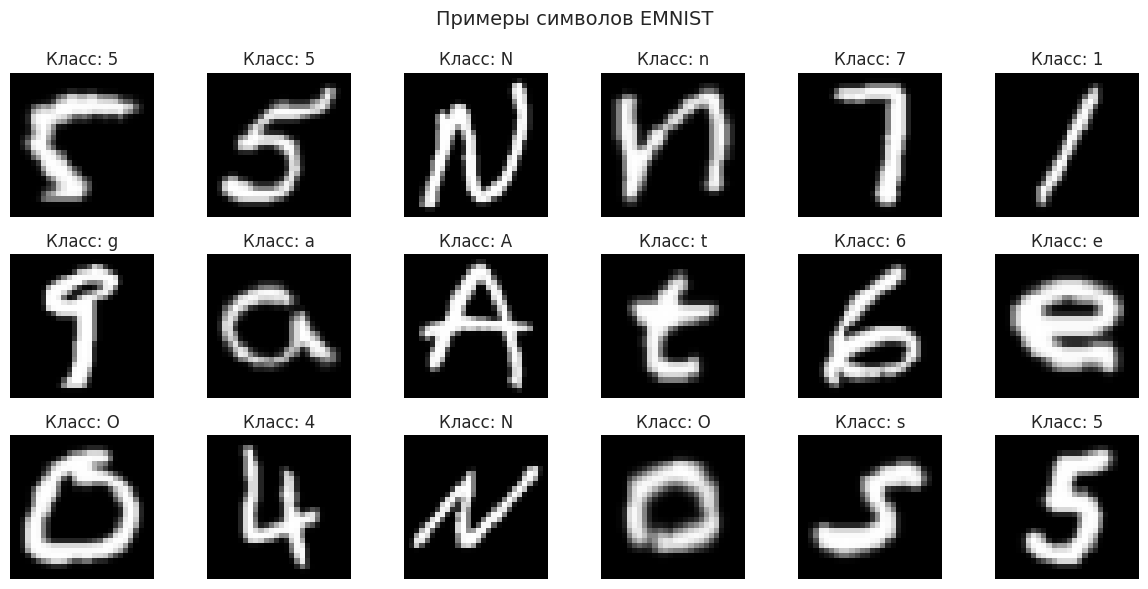

In [5]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6))

for axis, index in zip(axes.flat, train_indices[:18]):
    image, label = train_evaluation[index]
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(f"Класс: {class_names[label]}")
    axis.axis("off")

plt.suptitle("Примеры символов EMNIST", fontsize=14)
plt.tight_layout()
plt.show()

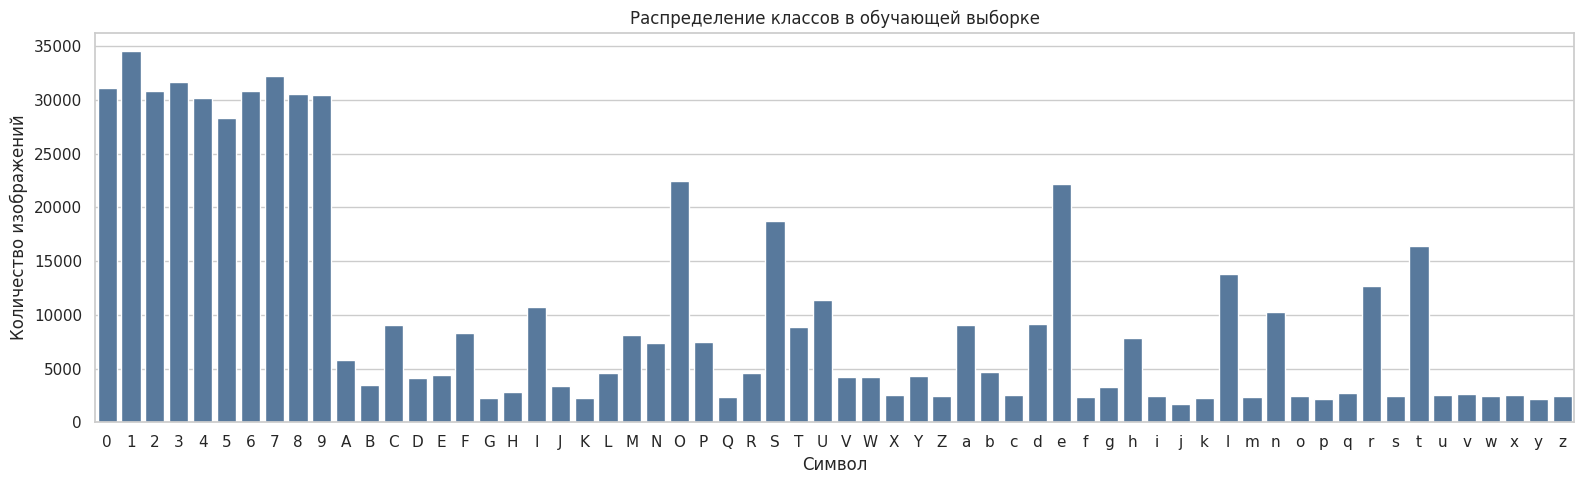

,Количество
count,62.0
mean,10131.3
std,10403.0
min,1706.0
25%,2505.5
50%,4567.0
75%,12356.0
max,34537.0


In [6]:
class_counts = pd.Series(targets[train_indices]).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Символ": [class_names[index] for index in class_counts.index],
    "Количество": class_counts.values
})

plt.figure(figsize=(16, 5))
sns.barplot(data=class_distribution, x="Символ", y="Количество", color="#4C78A8")
plt.title("Распределение классов в обучающей выборке")
plt.xlabel("Символ")
plt.ylabel("Количество изображений")
plt.tight_layout()
plt.show()

display(class_distribution.describe().round(1))

В EMNIST ByClass классы представлены неравномерно: часто встречающиеся цифры и буквы содержат больше примеров. Поэтому вместе с accuracy оценивается macro F1, который вычисляет качество отдельно для каждого класса, а затем усредняет результаты.

In [7]:
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

## Архитектура модели

Используется компактная CNN из трех сверточных блоков. Batch Normalization стабилизирует обучение, Dropout снижает риск переобучения, а Adaptive Average Pooling делает переход к полносвязному слою независимым от промежуточного размера карты признаков.

In [8]:
class CharacterCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((3, 3))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(128 * 3 * 3, 256),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CharacterCNN(len(class_names)).to(device)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

print(model)
print(f"Обучаемых параметров: {trainable_parameters:,}")

CharacterCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(3, 3))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.35, inplace=False)
    (2): Linear(in_features=1152, out_features=256, bias=True)
    (3): ReLU()
    (4): 

## Обучение

Оптимизируется Cross Entropy Loss с помощью AdamW. После каждой эпохи вычисляются loss и accuracy на валидации. Сохраняются веса с лучшей валидационной accuracy.

In [9]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_training else torch.no_grad()

    with context:
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, correct / total

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1
)

history = []
best_accuracy = 0.0
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_accuracy = run_epoch(model, val_loader, criterion)
    scheduler.step(val_accuracy)

    history.append({
        "Эпоха": epoch,
        "Train loss": train_loss,
        "Validation loss": val_loss,
        "Train accuracy": train_accuracy,
        "Validation accuracy": val_accuracy
    })

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_state = deepcopy(model.state_dict())

    print(
        f"Эпоха {epoch}/{EPOCHS} - "
        f"train loss: {train_loss:.4f}, "
        f"val loss: {val_loss:.4f}, "
        f"train accuracy: {train_accuracy:.3f}, "
        f"val accuracy: {val_accuracy:.3f}"
    )

model.load_state_dict(best_state)
torch.save(model.state_dict(), "character_cnn_emnist.pth")
print(f"Лучшая validation accuracy: {best_accuracy:.3f}")

  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/273 [00:00<?, ?it/s]

Эпоха 1/8 - train loss: 0.6289, val loss: 0.4052, train accuracy: 0.795, val accuracy: 0.853


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/273 [00:00<?, ?it/s]

...

  0%|          | 0/273 [00:00<?, ?it/s]

Эпоха 7/8 - train loss: 0.3970, val loss: 0.3472, train accuracy: 0.855, val accuracy: 0.870


  0%|          | 0/2454 [00:00<?, ?it/s]

  0%|          | 0/273 [00:00<?, ?it/s]

Эпоха 8/8 - train loss: 0.3933, val loss: 0.3447, train accuracy: 0.856, val accuracy: 0.871
Лучшая validation accuracy: 0.871


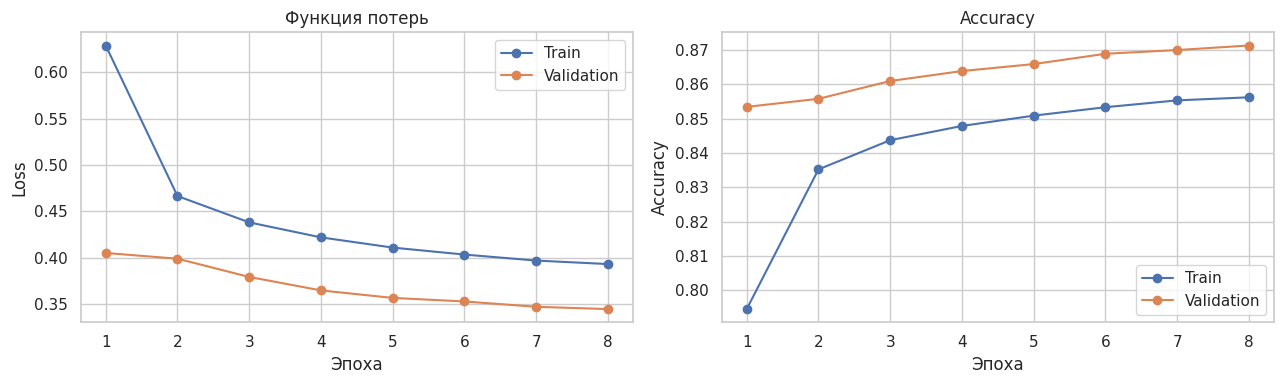

In [11]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["Эпоха"], history_df["Train loss"], marker="o", label="Train")
axes[0].plot(history_df["Эпоха"], history_df["Validation loss"], marker="o", label="Validation")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_df["Эпоха"], history_df["Train accuracy"], marker="o", label="Train")
axes[1].plot(history_df["Эпоха"], history_df["Validation accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## Оценка на тестовой выборке

Тестовая выборка используется один раз после выбора лучшей версии модели.

In [12]:
def collect_predictions(model, loader):
    model.eval()
    predictions = []
    targets = []
    probabilities = []

    with torch.no_grad():
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device, non_blocking=True)
            logits = model(images)
            batch_probabilities = logits.softmax(dim=1)

            predictions.extend(batch_probabilities.argmax(dim=1).cpu().numpy())
            probabilities.extend(batch_probabilities.max(dim=1).values.cpu().numpy())
            targets.extend(labels.numpy())

    return np.array(targets), np.array(predictions), np.array(probabilities)


y_true, y_pred, confidence = collect_predictions(model, test_loader)

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro F1": f1_score(y_true, y_pred, average="macro")
})

display(test_metrics.to_frame("Значение").round(4))

  0%|          | 0/455 [00:00<?, ?it/s]

,Значение
Accuracy,0.8717
Macro F1,0.7421


In [13]:
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_metrics = (
    pd.DataFrame(report)
    .T
    .iloc[:len(class_names)]
    .sort_values("f1-score")
)

display(class_metrics.head(12).round(3))

,precision,recall,f1-score,support
o,0.000,0.000,0.000,466.0
c,0.000,0.000,0.000,432.0
s,1.000,0.009,0.018,437.0
u,0.667,0.017,0.032,482.0
f,0.455,0.038,0.069,400.0
m,0.514,0.041,0.076,464.0
l,0.592,0.148,0.236,2535.0
v,0.598,0.321,0.417,468.0
p,0.587,0.386,0.466,368.0
i,0.876,0.365,0.516,427.0


Таблица показывает классы с самым низким F1-score. Основная сложность EMNIST ByClass - визуально похожие символы, например `0/O/o`, `1/I/l`, `5/S/s` и `C/c`.

## Анализ ошибок

In [14]:
matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
np.fill_diagonal(matrix, 0)

error_pairs = []

for true_index, predicted_index in zip(*np.unravel_index(
    np.argsort(matrix, axis=None)[-15:][::-1],
    matrix.shape
)):
    error_pairs.append({
        "Истинный символ": class_names[true_index],
        "Предсказанный символ": class_names[predicted_index],
        "Количество ошибок": matrix[true_index, predicted_index]
    })

display(pd.DataFrame(error_pairs))

,Истинный символ,Предсказанный символ,Количество ошибок
0,l,1,1919
1,O,0,1721
2,0,O,1131
3,I,1,1075
4,u,U,457
5,m,M,442
6,c,C,425
7,s,S,403
8,f,F,360
9,5,S,287


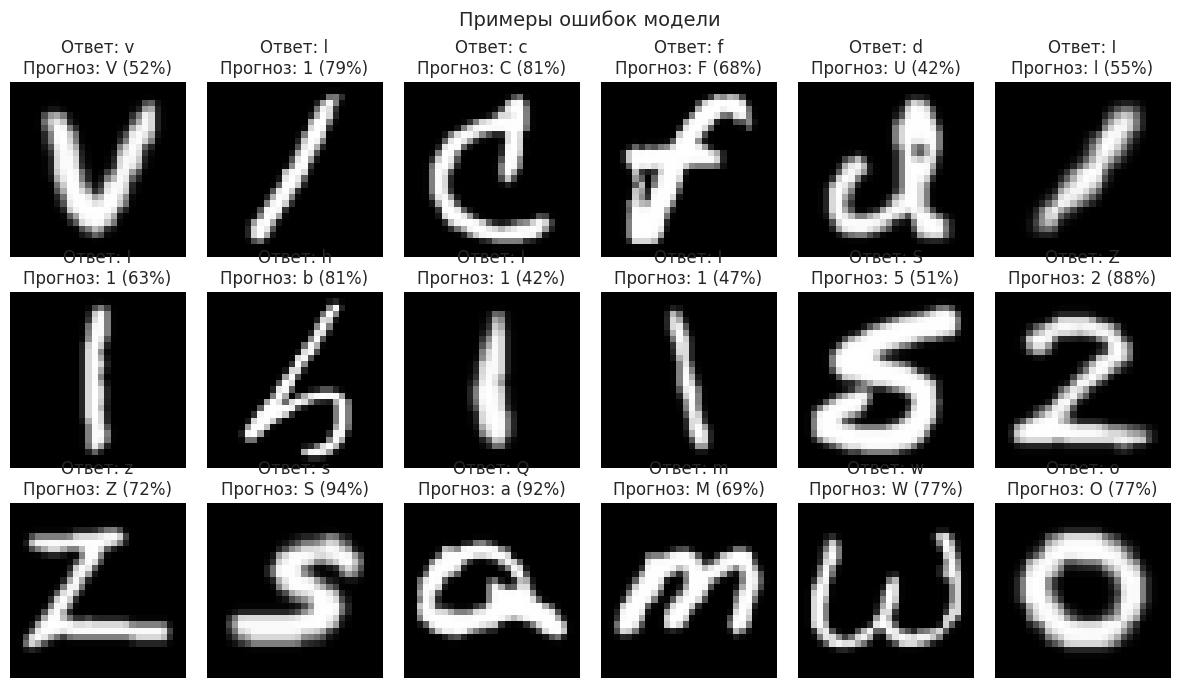

In [15]:
error_indices = np.flatnonzero(y_true != y_pred)
rng = np.random.default_rng(SEED)
selected_errors = rng.choice(error_indices, size=min(18, len(error_indices)), replace=False)

fig, axes = plt.subplots(3, 6, figsize=(12, 7))

for axis, result_index in zip(axes.flat, selected_errors):
    dataset_index = test_indices[result_index]
    image, _ = test_dataset[dataset_index]
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(
        f"Ответ: {class_names[y_true[result_index]]}\n"
        f"Прогноз: {class_names[y_pred[result_index]]} "
        f"({confidence[result_index]:.0%})"
    )
    axis.axis("off")

plt.suptitle("Примеры ошибок модели", fontsize=14)
plt.tight_layout()
plt.show()

## Примеры предсказаний

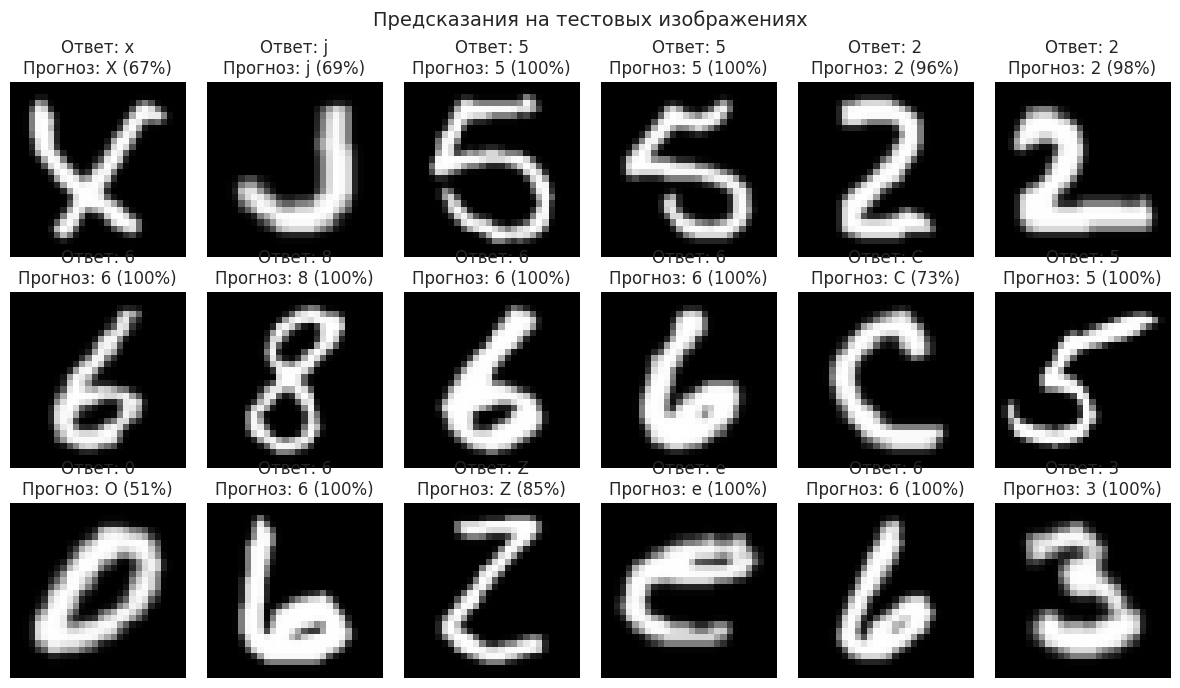

In [16]:
sample_indices = rng.choice(len(test_subset), size=18, replace=False)

fig, axes = plt.subplots(3, 6, figsize=(12, 7))

model.eval()

for axis, subset_index in zip(axes.flat, sample_indices):
    image, true_label = test_subset[subset_index]

    with torch.no_grad():
        probabilities = model(image.unsqueeze(0).to(device)).softmax(dim=1).squeeze()

    predicted_label = probabilities.argmax().item()
    predicted_confidence = probabilities[predicted_label].item()

    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(
        f"Ответ: {class_names[true_label]}\n"
        f"Прогноз: {class_names[predicted_label]} "
        f"({predicted_confidence:.0%})"
    )
    axis.axis("off")

plt.suptitle("Предсказания на тестовых изображениях", fontsize=14)
plt.tight_layout()
plt.show()

## Итоги

В проекте построен воспроизводимый pipeline классификации рукописных символов на полном датасете EMNIST ByClass:

- 628 138 изображений использованы для обучения;
- 69 794 изображения использованы для валидации;
- 116 323 изображения использованы для финального тестирования;
- ориентация изображений исправлена, к обучающей выборке применены небольшие аугментации;
- компактная CNN обучена в течение восьми эпох;
- лучшая validation accuracy составила 0,871;
- test accuracy составила 0,8717;
- test macro F1 составил 0,7421.

Модель уверенно распознает большую часть символов, однако часто путает визуально похожие классы: `l/1/I`, `0/O/o`, `5/S/s`, а также заглавные и строчные варианты некоторых букв. Это характерная сложность EMNIST ByClass: часть символов практически неразличима без контекста слова.

Классификатор может использоваться как компонент OCR-системы, но полноценное распознавание документов дополнительно требует надежной сегментации строк и символов, а также языковой модели для учета контекста.